In [ ]:
import numpy as np
import time

def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility
        scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource
        consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware
        capacity limits (b_i).
    """
    
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
    
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        # Maximum hardware capacity limits (length m)
        capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    return n, m, utilities, demands, capacities

if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5 (1).txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n}")
        print(f"Number of resource bounds (m) : {m}")
        print(f"Utility scores shape (p_j) : {utilities.shape}")
        print(f"Resource demands shape (r_ij) : {demands.shape}")
        print(f"Utility scores shape (p_j) : {utilities}")
        print(f"Resource demands shape (r_ij) : {demands}")
        print(f"Capacity limits (b_i) : {capacities}")
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

=== Dataset Ingestion Summary ===
Number of candidate models (n) : 90
Number of resource bounds (m) : 5
Utility scores shape (p_j) : (90,)
Resource demands shape (r_ij) : (5, 90)
Utility scores shape (p_j) : [360.  83.  59. 130. 431.  67. 230.  52.  93. 125. 670. 892. 600.  38.
  48. 147.  78. 256.  63.  17. 120. 164. 432.  35.  92. 110.  22.  42.
  50. 323. 514.  28.  87.  73.  78.  15.  26.  78. 210.  36.  85. 189.
 274.  43.  33.  10.  19. 389. 276. 312.  94.  68.  73. 192.  41. 163.
  16.  40. 195. 138.  73. 152. 400.  26.  14. 170. 205.  57. 369. 435.
 123.  25.  94.  88.  90. 146.  55.  29.  82.  74. 100.  72.  31.  29.
 316. 244.  70.  82.  90.  52.]
Resource demands shape (r_ij) : [[ 7.  0. 30. 22. 80. 94. 11. 81. 70. 64. 59. 18.  0. 36.  3.  8. 15. 42.
   9.  0. 42. 47. 52. 32. 26. 48. 55.  6. 29. 84.  2.  4. 18. 56.  7. 29.
  93. 44. 71.  3. 86. 66. 31. 65.  0. 79. 20. 65. 52. 13. 48. 14.  5. 72.
  14. 39. 46. 27. 11. 91. 15. 25.  0. 94. 53. 48. 27. 99.  6. 17. 69. 43.
   0. 

In [2]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        print("=== Dataset Ingestion Summary ===")
        print(f"Number of candidate models (n) : {n}")
        print(f"Number of resource bounds (m) : {m}")
        print(f"Utility scores shape (p_j) : {utilities.shape}")
        print(f"Resource demands shape (r_ij) : {demands.shape}")
        print(f"Utility scores shape (p_j) : {utilities}")
        print(f"Resource demands shape (r_ij) : {demands}")
        print(f"Capacity limits (b_i) : {capacities}")
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

=== Dataset Ingestion Summary ===
Number of candidate models (n) : 28
Number of resource bounds (m) : 2
Utility scores shape (p_j) : (28,)
Resource demands shape (r_ij) : (2, 28)
Utility scores shape (p_j) : [ 1898.   440. 22507.   270. 14148.  3100.  4650. 30800.   615.  4975.
  1160.  4225.   510. 11880.   479.   440.   490.   330.   110.   560.
 24355.  2885. 11748.  4550.   750.  3720.  1950. 10500.]
Resource demands shape (r_ij) : [[ 45.   0.  85. 150.  65.  95.  30.   0. 170.   0.  40.  25.  20.   0.
    0.  25.   0.   0.  25.   0. 165.   0.  85.   0.   0.   0.   0. 100.]
 [ 30.  20. 125.   5.  80.  25.  35.  73.  12.  15.  15.  40.   5.  10.
   10.  12.  10.   9.   0.  20.  60.  40.  50.  36.  49.  40.  19. 150.]]
Capacity limits (b_i) : [500. 500.]


In [3]:
import matplotlib.pyplot as plt
import random
np.random.seed(42)

def TungTungSahur(utilities, demands):
    result=np.random.randint(0,2,size=len(utilities))
    brainrot=utilities @ result
    brain_cap=demands @ result
    return brainrot,brain_cap,result

def SahurOrAssasino(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=None):
    if np.all(brain_cap <= capacities) and brainrot>bestie:
        bestie = brainrot
        bestie_res = result

    return bestie,bestie_res
    
def lol(n, m, utilities, demands, capacities):
    log=[]
    for lol in range(1, 6767):
        brainrot,brain_cap,result= TungTungSahur(utilities, demands)
        if lol==1:
            bestie,bestie_res =SahurOrAssasino(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=np.zeros(n, dtype=int))
        else:
            bestie,bestie_res =SahurOrAssasino(capacities,brainrot,result,brain_cap, bestie=bestie,bestie_res=bestie_res)
            
        log.append({'lol':lol,'score':bestie})
        
    return bestie,bestie_res,log

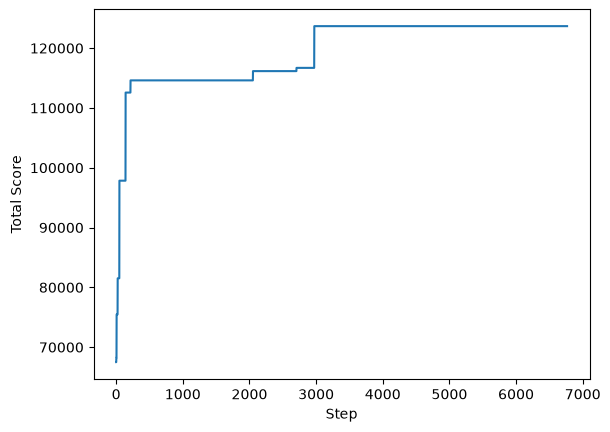

123677.0
[0 0 1 0 1 0 1 1 0 0 1 0 0 1 1 0 0 0 0 0 1 0 1 0 0 0 1 0]
[470. 477.]


In [4]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=lol(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log])
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.show()
        print(bestie)
        print(bestie_res)
        print(demands @ bestie_res) 
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

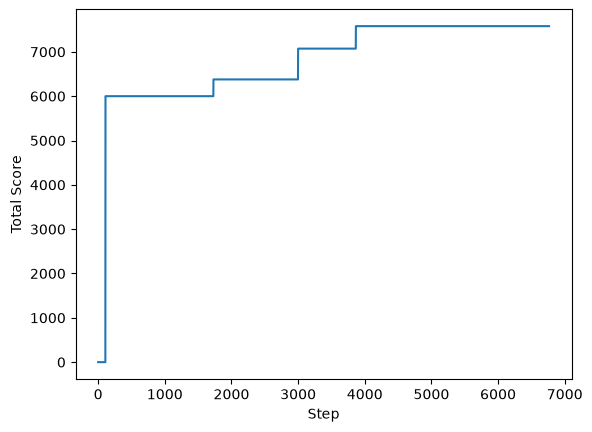

7580.0
[1 1 0 0 1 1 0 0 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 1 0 1 1 1 1 0 0 0 1
 0 1 0 0 1 1 0 1 0 1 0 1 1 0 0 0 0 1 1 0 1 1 0 1 1 1 0 1 0 0 1 1 0 0 0 0 1
 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0]
[1353. 1007. 1551. 1871. 1772.]


In [5]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5 (1).txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=lol(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log])
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.show()
        print(bestie)
        print(bestie_res)
        print(demands @ bestie_res) 
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

In [6]:
def CapuchinoAssassino(utilities, demands, capacities):
    result=np.random.randint(0,2,size=len(utilities))
    usage=demands @ result
    
    if not np.all(usage <= capacities):
        eff=utilities/((demands/capacities[:,None]).sum(axis=0)+1e-9)
        order=np.argsort(-eff)
        for k in order[::-1]:
            if np.all(usage <= capacities):
                break
            if result[k]==1:
                result[k]=0
                usage=usage-demands[:,k]
        for k in order:
            if result[k]==0 and np.all(usage+demands[:,k] <= capacities):
                result[k]=1
                usage=usage+demands[:,k]
    brainrot=utilities @ result
    brain_cap=demands @ result
    return brainrot,brain_cap,result

def SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=None):
    if brainrot>=bestie:
        bestie = brainrot
        bestie_res = result

    return bestie,bestie_res
    
def league_of_legends(n, m, utilities, demands, capacities):
    log=[]
    for lol in range(1, 6767):
        brainrot,brain_cap,result= CapuchinoAssassino(utilities, demands,capacities)
        if lol==1:
            bestie,bestie_res =SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=0,bestie_res=np.zeros(n, dtype=int))
        else:
            bestie,bestie_res =SahurOrAssasino2(capacities,brainrot,result,brain_cap, bestie=bestie,bestie_res=bestie_res)
            
        log.append({'lol':lol,'score':bestie})
    
    return bestie,bestie_res,log

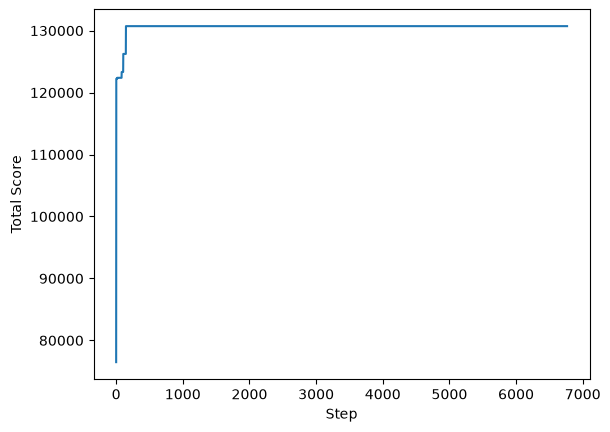

130723.0
[0 0 1 0 1 0 1 1 0 1 0 0 1 1 0 0 1 0 1 0 1 0 1 1 0 0 0 0]
[475. 499.]


In [7]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n28_m2.txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log])
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.show()
        print(bestie)
        print(bestie_res)
        print(demands @ bestie_res) 
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

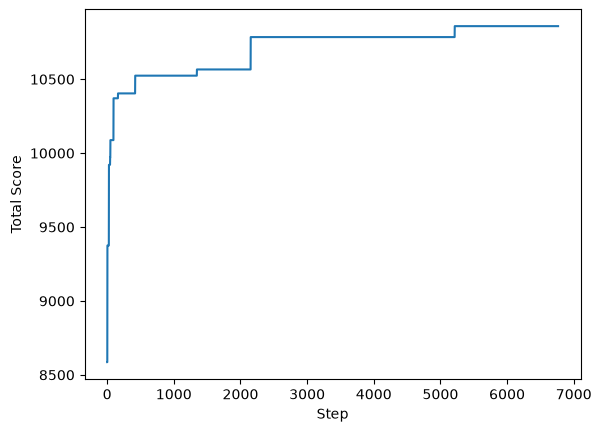

10859.0
[1 0 0 0 1 0 1 0 1 0 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 1 0 1 1 1 0 0
 0 1 0 0 1 1 0 0 0 0 1 0 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 0 1 1 1 0 1 0
 0 1 0 1 1 1 0 0 0 0 1 1 0 1 0 1]
[1703. 1097. 2105. 1959. 2243.]


In [8]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5 (1).txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log])
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.show()
        print(bestie)
        print(bestie_res)
        print(demands @ bestie_res) 
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

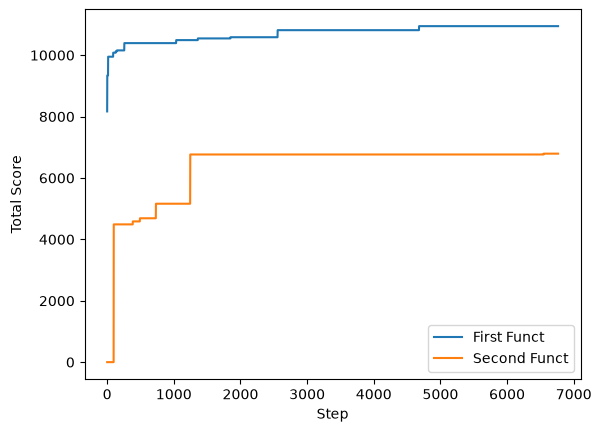

In [9]:
if __name__ == "__main__":
    # Example usage demonstration
    sample_file = "multi_resource_n90_m5 (1).txt"
    
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
        bestie2,bestie_res2,log2=lol(n, m, utilities, demands, capacities)
        plt.plot([lmao['score'] for lmao in log],label="First Funct")
        plt.plot([lmao['score'] for lmao in log2],label="Second Funct")
        plt.xlabel("Step")
        plt.ylabel("Total Score")
        plt.legend()
        plt.show()
        
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")

In [ ]:
# # uncomment if want to test every run :P

# if __name__ == "__main__":
#     # Example usage demonstration
#     sample_file = "multi_resource_n90_m5 (1).txt"
    
#     try:
#         n, m, utilities, demands, capacities = load_workload_instance(sample_file)
#         timeimproved_func=[]
#         time_beforefunc=[]
#         for lmao in range(30):
#             start = time.time()
#             bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
#             end = time.time()
#             res_impprovedFunctime=end-start
#             timeimproved_func.append(res_impprovedFunctime)
#             print(f'Improved function took: {res_impprovedFunctime:.2f}')
#             print(f'{bestie} \n')
            
#             start = time.time()
#             bestie2,bestie_res2,log2=lol(n, m, utilities, demands, capacities)
#             end = time.time()
#             res_innitialFunctime=end-start
#             time_beforefunc.append(res_innitialFunctime)
#             print(f'Random search function took: {res_innitialFunctime:.2f}')
#             print(bestie2)
#             plt.plot([lmao['score'] for lmao in log],label="Improved Function")
#             plt.plot([lmao['score'] for lmao in log2],label="Random search Function")
#             plt.xlabel("Step")
#             plt.ylabel("Total Score")
#             plt.legend()
#             plt.show()
        
#     except FileNotFoundError:
#         print(f"Please provide a valid path to {sample_file}")

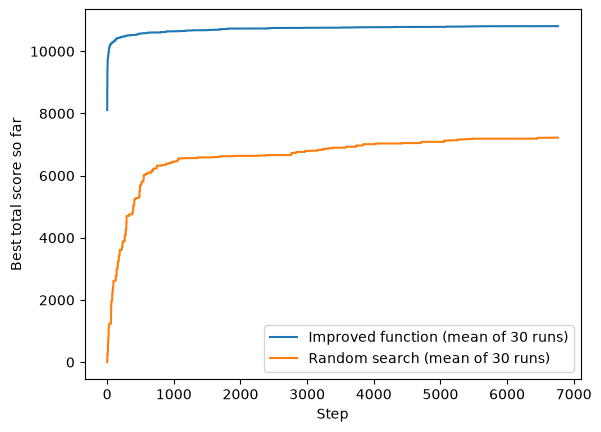

Improved function time 0.89s, mean final score 10810
Random function time 0.03s, mean final score 7222


In [ ]:
if __name__ == "__main__":
    sample_file = "multi_resource_n90_m5 (1).txt"
    try:
        n, m, utilities, demands, capacities = load_workload_instance(sample_file)
        timeimproved_func=[]
        time_beforefunc=[]
        logs_improved=[]
        logs_random=[]
        for run in range(30):
            start = time.time()
            bestie,bestie_res,log=league_of_legends(n, m, utilities, demands, capacities)
            timeimproved_func.append(time.time()-start)
            logs_improved.append([lmao['score'] for lmao in log])

            start = time.time()
            bestie2,bestie_res2,log2=lol(n, m, utilities, demands, capacities)
            time_beforefunc.append(time.time()-start)
            logs_random.append([lmao['score'] for lmao in log2])

        plt.plot(np.mean(logs_improved,axis=0),label="Improved function (mean of 30 runs)")
        plt.plot(np.mean(logs_random,axis=0),label="Random search (mean of 30 runs)")
        plt.xlabel("Step")
        plt.ylabel("Total score so far")
        plt.legend()
        plt.show()

        print(f"Improved function took {np.mean(timeimproved_func):.2f}s, mean final score {np.mean([l[-1] for l in logs_improved]):.0f}")
        print(f"Random function took {np.mean(time_beforefunc):.2f}s, mean final score {np.mean([l[-1] for l in logs_random]):.0f}")
    
    except FileNotFoundError:
        print(f"Please provide a valid path to {sample_file}")